# Bibliotecas

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
import itertools
import statsmodels.api as sm

# Importação e análise dos datasets

In [ ]:
df_errors = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_errors.csv', sep=',', encoding='utf-8')
df_failures = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_failures.csv', sep=',', encoding='utf-8')
df_machines = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_machines.csv', sep=',', encoding='utf-8')
df_maint = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_maint.csv', sep=',', encoding='utf-8')
df_telemetry = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_telemetry.csv', sep=',', encoding='utf-8')

## Informações dos datasets

* Telemetry Time Series Data (PdM_telemetry.csv): It consists of hourly average of voltage, rotation, pressure, vibration collected from 100 machines for the year 2015.

* Error (PdM_errors.csv): These are errors encountered by the machines while in operating condition. Since, these errors don't shut down the machines, these are not considered as failures. The error date and times are rounded to the closest hour since the telemetry data is collected at an hourly rate.

* Maintenance (PdM_maint.csv): If a component of a machine is replaced, that is captured as a record in this table. Components are replaced under two situations: 1. During the regular scheduled visit, the technician replaced it (Proactive Maintenance) 2. A component breaks down and then the technician does an unscheduled maintenance to replace the component (Reactive Maintenance). This is considered as a failure and corresponding data is captured under Failures. Maintenance data has both 2014 and 2015 records. This data is rounded to the closest hour since the telemetry data is collected at an hourly rate.

* Failures (PdM_failures.csv): Each record represents replacement of a component due to failure. This data is a subset of Maintenance data. This data is rounded to the closest hour since the telemetry data is collected at an hourly rate.

* Metadata of Machines (PdM_Machines.csv): Model type & age of the Machines.

In [ ]:
df_errors.head()

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4


In [ ]:
df_failures.head()

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4


In [ ]:
df_machines.head()

,machineID,model,age
0,1,model3,18
1,2,model4,7
2,3,model3,8
3,4,model3,7
4,5,model3,2


In [ ]:
df_maint.head()

,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4


In [ ]:
df_telemetry.head()

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


# Análise de uma máquina

In [ ]:
id_maquina = 13

In [ ]:
df_falhas = df_failures.loc[df_failures['machineID'] == id_maquina].reset_index(drop=True)
df_falhas.head()

,datetime,machineID,failure
0,2015-04-11 06:00:00,13,comp3
1,2015-04-11 06:00:00,13,comp4
2,2015-06-10 06:00:00,13,comp3
3,2015-06-25 06:00:00,13,comp4
4,2015-07-10 06:00:00,13,comp2


In [ ]:
df_erros = df_errors.loc[df_errors['machineID'] == id_maquina].reset_index(drop=True)
df_erros.head()

,datetime,machineID,errorID
0,2015-01-10 04:00:00,13,error5
1,2015-01-13 21:00:00,13,error3
2,2015-01-26 09:00:00,13,error2
3,2015-01-27 07:00:00,13,error1
4,2015-01-28 20:00:00,13,error1


In [ ]:
df_maquina = df_telemetry.loc[df_telemetry['machineID'] == id_maquina].reset_index(drop=True)

# Datetime como index
df_maquina['datetime'] = pd.to_datetime(df_maquina['datetime'], format='%Y-%m-%d %H:%M:%S')
df_maquina.set_index('datetime', drop=True, inplace=True)

df_maquina.head()

# df_maquina.shape
# (8761, 5)

,machineID,volt,rotate,pressure,vibration
datetime,,,,,
2015-01-01 06:00:00,13,155.172892,456.320444,96.090782,32.522588
2015-01-01 07:00:00,13,183.752447,439.656853,102.744687,37.099813
2015-01-01 08:00:00,13,174.731896,399.487309,114.171005,34.519719
2015-01-01 09:00:00,13,159.881546,461.922370,95.503275,43.790212
2015-01-01 10:00:00,13,174.588451,459.084780,94.029010,41.195627


Dataset começa em 2015-01-01 06:00:00 e termina em 2016-01-01 06:00:00

## Análise gráfica

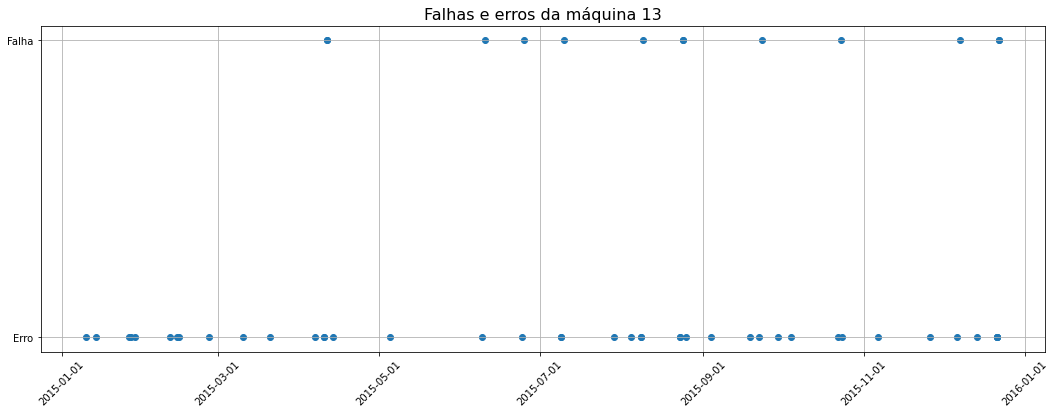

In [ ]:
fig, ax = plt.subplots()

# For a simpler plot, we will use two different values in the y-axis to differentiate between error and failure
y_category = list()

for iter in range(0, len(df_falhas)):
  y_category.append('Falha')

for iter in range(0, len(df_erros)):
  y_category.append('Erro')

# Get timestamp from error and selected failure
df_timestamp = pd.concat([df_falhas['datetime'], df_erros['datetime']], ignore_index=True, axis=0)
df_plot = pd.DataFrame({'timestamp': df_timestamp, 'category': y_category})
df_plot.loc[:, 'timestamp'] = pd.to_datetime(df_plot.loc[:, 'timestamp'])
df_plot.sort_values(by=['timestamp'], inplace=True, ignore_index=True)


# Plot the data with timestamp as x-axis
ax.scatter('timestamp', 'category', data = df_plot)
yearfmt = mdates.DateFormatter('%Y-%m-%d')
ax.set_title('Falhas e erros da máquina 13', fontsize=16)
ax.xaxis.set_major_formatter(yearfmt)
ax.tick_params(axis='x', rotation=45)
ax.figure.set_size_inches(18, 6)
ax.grid()

## Conclusão

As falhas ocorreram após alguns erros.

Alguns erros resultaram em falhas imediatas.

In [ ]:
df_plot.groupby('category').count()

,timestamp
category,
Erro,42
Falha,13


# Análise de estacionariedade

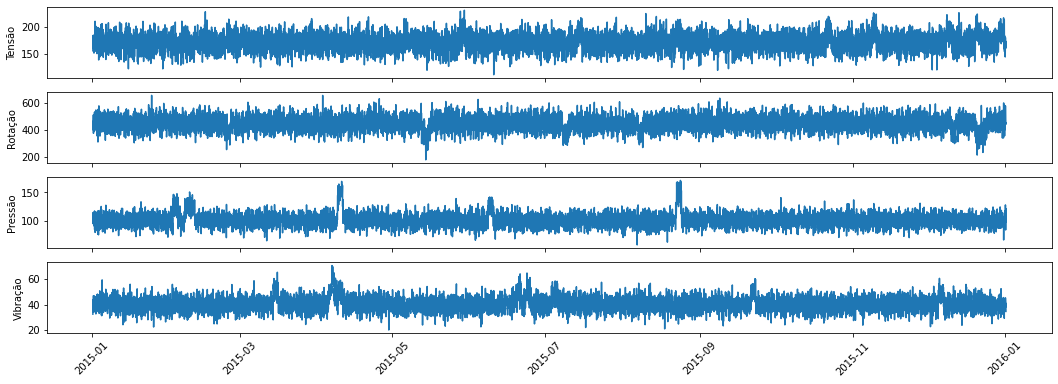

In [ ]:
fig, ax = plt.subplots(nrows=4, sharex=True)
fig.set_size_inches(18, 6)

ax[0].plot('volt', data=df_maquina)
ax[0].set_ylabel('Tensão')

ax[1].plot('rotate', data=df_maquina)
ax[1].set_ylabel('Rotação')

ax[2].plot('pressure', data=df_maquina)
ax[2].set_ylabel('Pressão')

ax[3].plot('vibration', data=df_maquina)
ax[3].set_ylabel('Vibração')
ax[3].tick_params(axis='x', rotation=45)

## Conclusão

A pressão foi a grandeza que sofreu anormalidade mais notável.

Ela será a variável preditora do modelo.

# Dataset [pressão]

In [ ]:
df_maquina_original = df_maquina

df_maquina = df_maquina[0:2628] # Dados para aprendizado (30% do total de dados)

In [ ]:
y = df_maquina['pressure']

## Análise de estacionariedade da pressão

Text(0.5, 0, '')

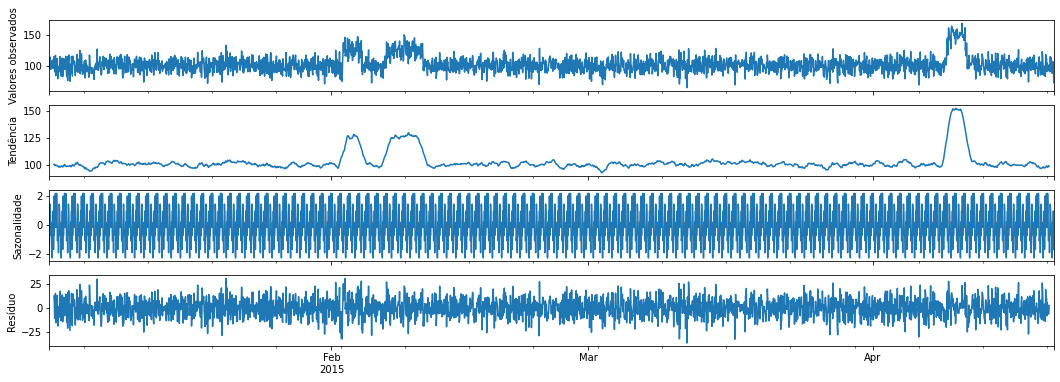

In [ ]:
periodo_sazonal = 24 # Horas

resultados = seasonal_decompose(y, period=periodo_sazonal)

fig, (ax1,ax2,ax3, ax4) = plt.subplots(4, figsize=(18, 6), sharex=True)
fig.set_size_inches(18, 6)

ax1 = resultados.observed.plot(ax=ax1) # Valores observados
ax1.set_ylabel('Valores observados')

ax2 = resultados.trend.plot(ax=ax2) # Tendência
ax2.set_ylabel('Tendência')

ax3 = resultados.seasonal.plot(ax=ax3) # Sazonalidade
ax3.set_ylabel('Sazonalidade')

ax4 = resultados.resid.plot(ax=ax4) # Resíduo
ax4.set_ylabel('Resíduo')
ax4.set_xlabel(None)

## Teste de Dickey-Fuller

In [ ]:
p_valor = adfuller(y.dropna())[1]

significancia= 0.05

if p_valor > significancia:
    print('Série temporal não estacionária')
else:
    print('Série temporal estacionária')

Série temporal estacionária


## Autocorrelação

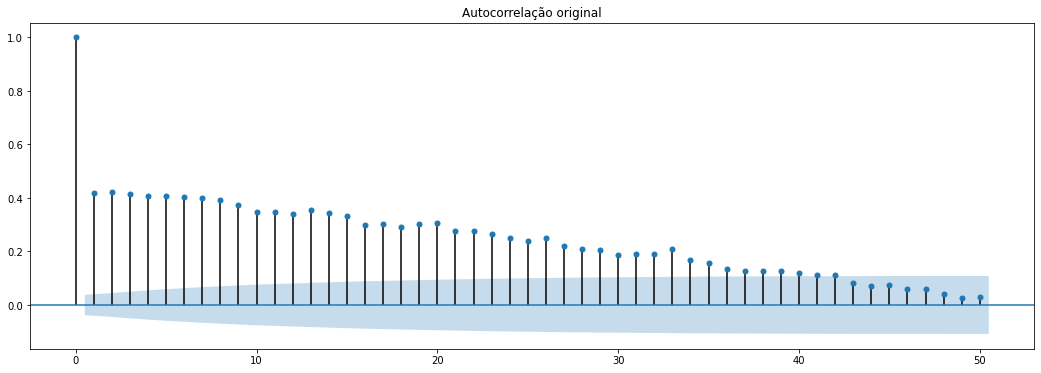

In [ ]:
autocorr = plot_acf(y, lags=50, title='Autocorrelação original', alpha=significancia)
autocorr.set_figheight(6)
autocorr.set_figwidth(18)
plt.show()

Dados altamente correlacionados até 40 lags.

## Autocorrelação parcial

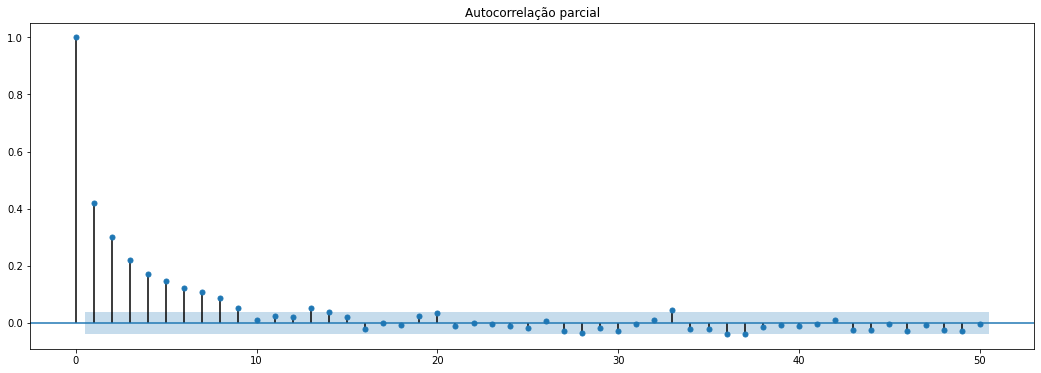

In [ ]:
autocorr_parc = plot_pacf(y, lags=50, title='Autocorrelação parcial', alpha=significancia)
autocorr_parc.set_figheight(6)
autocorr_parc.set_figwidth(18)
plt.show()

# ARIMA

## Parâmetros p, d, q, AIC

**AIC**

Utilizada para avaliar a qualidade do ajuste de modelo.

Compara o resultado obtido e a distância até o modelo estatístico real.

In [ ]:
p = d = q = range(0,2)

In [ ]:
pdq = list(itertools.product(p, d, q))
pdq

[(0, 0, 0),
 (0, 0, 1),
 (0, 1, 0),
 (0, 1, 1),
 (1, 0, 0),
 (1, 0, 1),
 (1, 1, 0),
 (1, 1, 1)]

In [ ]:
pdq_aic = []

for param in pdq:
    modelo = ARIMA(y, order=param)
    results = modelo.fit()
    pdq_aic.append('ARIMA {} - AIC {}'.format(param, results.aic))

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so in

In [ ]:
pdq_aic

['ARIMA (0, 0, 0) - AIC 21076.02448824318',
 'ARIMA (0, 0, 1) - AIC 20761.59776501251',
 'ARIMA (0, 1, 0) - AIC 21455.160936280146',
 'ARIMA (0, 1, 1) - AIC 19983.264036217028',
 'ARIMA (1, 0, 0) - AIC 20568.762494969662',
 'ARIMA (1, 0, 1) - AIC 19969.3550887739',
 'ARIMA (1, 1, 0) - AIC 20692.863731056157',
 'ARIMA (1, 1, 1) - AIC 19983.92833338405']

## Obtendo o menor AIC e respectivos parâmetros p, d, q

In [ ]:
aic_valores = []

for i in pdq_aic:
    aic = i.split('AIC ')
    aic_valores.append(float(aic[1]))

In [ ]:
menor_aic = min(aic_valores)

for i in pdq_aic:
    if str(menor_aic) in i:
        print(i)

ARIMA (1, 0, 1) - AIC 19969.3550887739


In [ ]:
modelo = ARIMA(y, order=(1, 0, 1))

modelo_fit = modelo.fit()

modelo_fit.summary()

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:               pressure   No. Observations:                 2628
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -9980.678
Date:                Mon, 09 Jan 2023   AIC                          19969.355
Time:                        21:11:54   BIC                          19992.851
Sample:                    01-01-2015   HQIC                         19977.864
                         - 04-20-2015                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        102.4492      1.700     60.260      0.000      99.117     105.781
ar.L1          0.9793      0.004    233.947      0.000       0.971       0.987
ma.L1         -0.8333      0.011    -77.745      0.000      -0.854      -0.812
sigma2       116.4453      3.101     37.551      0.000     110.367     122.523
===================================================================================
Ljung-Box (L1) (Q):                   1.60   Jarque-Bera (JB):                 7.43
Prob(Q):                              0.21   Prob(JB):                         0.02
Heteroskedasticity (H):               0.99   Skew:                             0.06
Prob(H) (two-sided):                  0.86   Kurtosis:                         3.23
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

## Diagnóstico do modelo

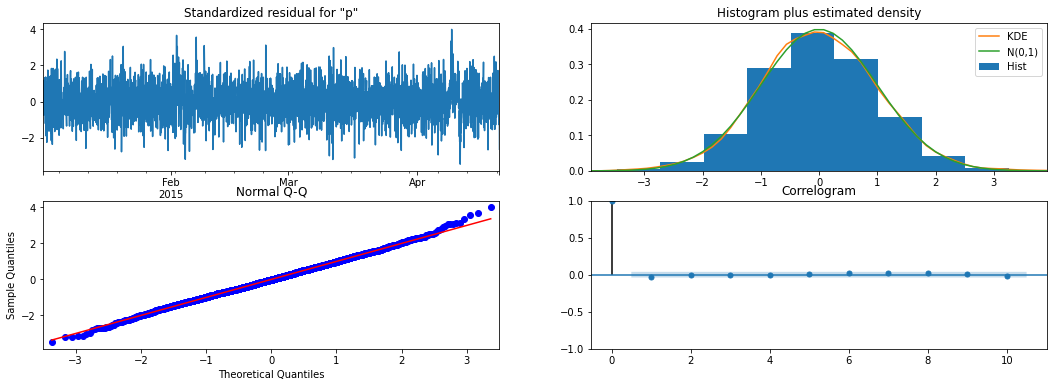

In [ ]:
modelo_fit.plot_diagnostics(figsize=(18, 6));

* Standardized residual - quantidade de resíduos em função da série temporal

* Histogram plus estimated desity - N (distribuição normal), KDE (distribuição dos resíduos) - espera-se que a distribuição dos resíduos se aproxime da normal

* Normal Q-Q - medida estatística de comparação entre quantis

* Correlograma - mostra as autocorrelações residuais - mostra que o modelo transformou (ou manteve) a série temporal como estacionária

# Previsão de valores

## Dados do passado

In [ ]:
pred = modelo_fit.get_prediction(start=pd.to_datetime('2015-01-01 06:00:00'), dynamic=False)

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:132: FutureWarning: The 'freq' argument in Timestamp is deprecated and will be removed in a future version.
  date_key = Timestamp(key, freq=base_index.freq)


## Intervalo de confiança

Valores preditos dentro do intevalo de confiança são considerados aceitáveis para o modelo.

In [ ]:
interval_conf = pred.conf_int()

interval_conf

,lower pressure,upper pressure
2015-01-01 06:00:00,76.376410,128.521943
2015-01-01 07:00:00,76.181451,123.236899
2015-01-01 08:00:00,78.179123,123.209670
2015-01-01 09:00:00,82.021668,126.015005
2015-01-01 10:00:00,80.509970,123.904698
2015-01-01 11:00:00,79.166466,122.191926
2015-01-01 12:00:00,80.365849,123.154124
2015-01-01 13:00:00,79.644107,122.276069
2015-01-01 14:00:00,78.987469,121.514667
2015-01-01 15:00:00,80.496121,122.952311


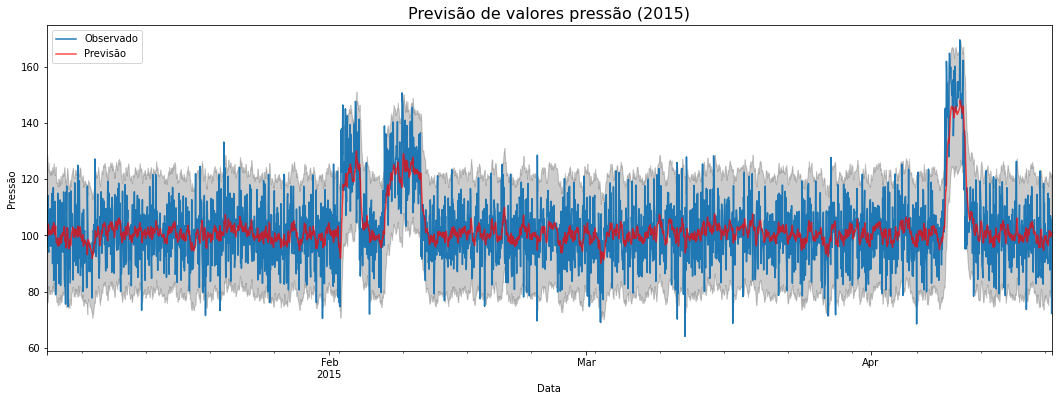

In [ ]:
# Dados da pressão no ano de 2015
ax = y['2015-01-01': '2015-12-31'].plot(label='Observado')

# Média móvel da predição
pred.predicted_mean.plot(ax=ax,
                         label='Previsão',
                         color='red',
                         alpha=0.7,
                         figsize=(18, 6))

# Intervalo de confiança
ax.fill_between(interval_conf.index,
                interval_conf.iloc[:, 0],
                interval_conf.iloc[:, 1],
                color='black',
                alpha=0.2)

ax.set_title('Previsão de valores pressão (2015)', fontsize=16)
ax.set_xlabel('Data')
ax.set_ylabel('Pressão')
plt.legend()

## Prevendo o futuro

In [ ]:
pred_futuro = modelo_fit.get_forecast(steps=720) # steps = tempo à frente para previsão (24 horas * 30 dias)

interval_conf_futuro = pred_futuro.conf_int()

interval_conf_futuro

,lower pressure,upper pressure
2015-04-20 18:00:00,75.527402,117.827267
2015-04-20 19:00:00,75.422863,118.170839
2015-04-20 20:00:00,75.327216,118.500568
2015-04-20 21:00:00,75.239813,118.817207
2015-04-20 22:00:00,75.160061,119.121449
2015-04-20 23:00:00,75.087415,119.413935
2015-04-21 00:00:00,75.021378,119.695261
2015-04-21 01:00:00,74.961489,119.965980
2015-04-21 02:00:00,74.907325,120.226609
2015-04-21 03:00:00,74.858494,120.477629


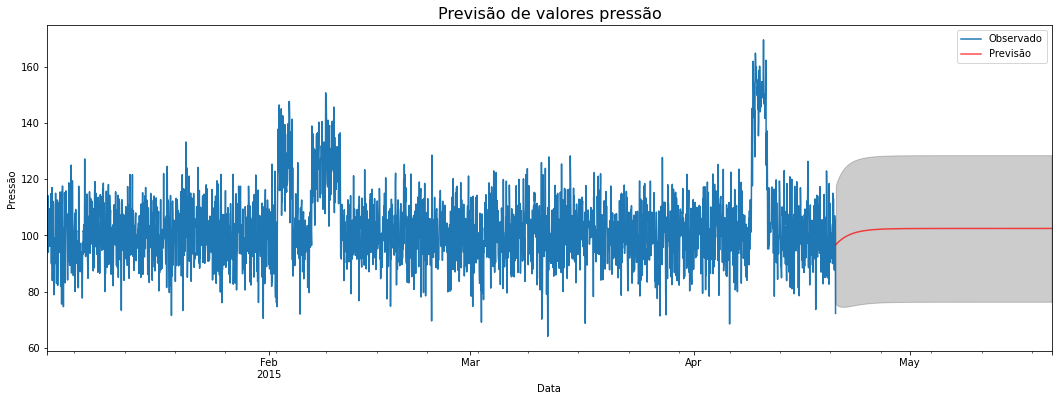

In [ ]:
# Previsão de valores da pressão
ax = y.plot(label='Observado')

# Média móvel da predição
pred_futuro.predicted_mean.plot(ax=ax,
                                label='Previsão',
                                color='red',
                                alpha=0.7,
                                figsize=(18, 6))

# Intervalo de confiança
ax.fill_between(interval_conf_futuro.index,
                interval_conf_futuro.iloc[:, 0],
                interval_conf_futuro.iloc[:, 1],
                color='black',
                alpha=0.2)

ax.set_title('Previsão de valores pressão', fontsize=16)
ax.set_xlabel('Data')
ax.set_ylabel('Pressão')
plt.legend()

## Comparação entre valores reais e previstos

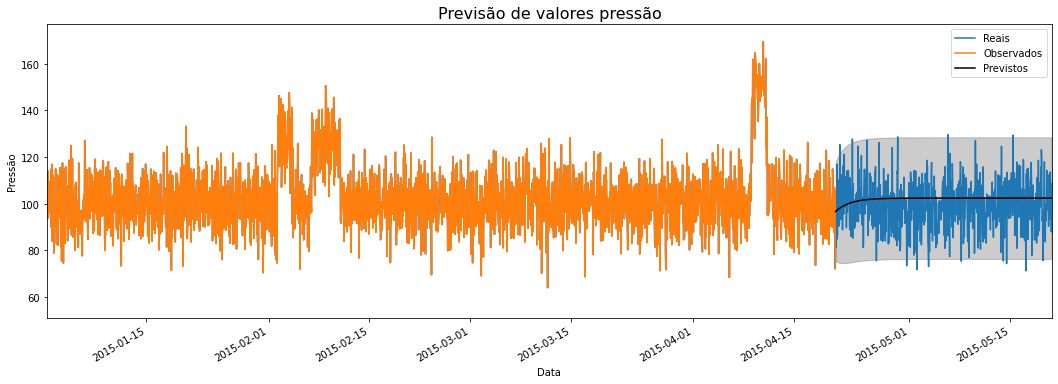

In [ ]:
x = df_maquina_original['pressure']

plt.figure(figsize=(18, 6))
fig = plt.plot(x, label=('Reais'))

ax = y.plot(label='Observados')

pred_futuro.predicted_mean.plot(ax=ax, label='Previstos', color='black')

ax.fill_between(interval_conf_futuro.index,
                interval_conf_futuro.iloc[:, 0],
                interval_conf_futuro.iloc[:, 1],
                color='black',
                alpha=0.2)

ax.set_title('Previsão de valores pressão', fontsize=16)
ax.set_xlabel('Data')
ax.set_ylabel('Pressão')

plt.xlim('2015-01-01 06:00:00', '2015-05-20 18:00:00')
plt.legend()